# Генерация карты из спутникового снимка (pix2pix)
**Архитектура: Conditional GAN (cGAN / pix2pix)**

**Задача:** Image-to-Image translation. На вход подается спутниковый снимок, на выходе — схематическая карта с дорогами, зданиями и лесами.

**Особенности архитектуры:**
1. **Генератор (U-Net):** Используем U-Net с skip-connections. Спутниковый снимок и карта имеют одинаковую геометрическую структуру (одни и те же дороги и дома). Пропускные соединения (skip connections) позволяют передавать низкоуровневую информацию (границы) напрямую из энкодера в декодер, не теряя ее в узком горлышке (bottleneck).
2. **Дискриминатор (PatchGAN):** Вместо того чтобы классифицировать всю картинку целиком (real/fake), он разбивает ее на сетку патчей (например, 70x70) и классифицирует каждый патч. Это заставляет сеть генерировать локально резкие текстуры.
3. **Функция потерь:** Используется стандартная состязательная потеря (cGAN Loss) + **L1 Loss** (попиксельная разница между сгенерированной картой и оригиналом). L1-потеря заставляет сеть точно следовать контурам, а GAN-потеря делает картинку резкой и реалистичной.

*Датасет: Berkeley pix2pix maps (спутниковые снимки и их карты).*

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset, Subset
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import tarfile
import urllib.request
import glob
import random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

BATCH_SIZE = 8
EPOCHS = 30
LR = 2e-4
IMAGE_SIZE = 256
LAMBDA_L1 = 100

Используемое устройство: cuda


## 1. Подготовка данных


In [2]:
# Скачивание датасета
url = "http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/maps.tar.gz"
data_dir = "./data"
os.makedirs(data_dir, exist_ok=True)
archive_path = os.path.join(data_dir, "maps.tar.gz")

if not os.path.exists(archive_path):
    print("Скачивание датасета (239 МБ)...")
    urllib.request.urlretrieve(url, archive_path)
    print("Распаковка...")
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path=data_dir)
    print("Готово!")

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

class Pix2PixDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.image_paths = glob.glob(os.path.join(root_dir, "*.jpg"))
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        w, h = img.size

        sat_img = img.crop((0, 0, w // 2, h))
        map_img = img.crop((w // 2, 0, w, h))

        if self.transform:
            sat_img = self.transform(sat_img)
            map_img = self.transform(map_img)

        return sat_img, map_img

full_dataset = Pix2PixDataset(root_dir=os.path.join(data_dir, "maps/train"), transform=transform)
train_dataset = full_dataset

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
print(f"Размер тренировочного набора: {len(train_dataset)} пар изображений")

Размер тренировочного набора: 1096 пар изображений


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## 2. Генератор (U-Net)
Архитектура состоит из **Энкодера** (сжимает изображение, выделяя признаки) и **Декодера** (восстанавливает изображение).
Ключевая особенность — **Skip Connections**: конкатенируем (объединяем) карты признаков энкодера с картами признаков декодера на соответствующих уровнях. Это позволяет сети не терять мелкие детали (например, тонкие дороги).

In [3]:
class UNetDown(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super(UNetDown, self).__init__()
        layers = [nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False)]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2))
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super(UNetUp, self).__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        ]
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip_input):
        x = self.model(x)
        x = torch.cat((x, skip_input), 1)
        return x

class GeneratorUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super(GeneratorUNet, self).__init__()
        # Encoder (Downsampling)
        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512, dropout=0.5)
        self.down5 = UNetDown(512, 512, dropout=0.5)
        self.down6 = UNetDown(512, 512, dropout=0.5)
        self.down7 = UNetDown(512, 512, dropout=0.5)
        self.down8 = UNetDown(512, 512, normalize=False, dropout=0.5)

        # Decoder (Upsampling)
        self.up1 = UNetUp(512, 512, dropout=0.5)
        self.up2 = UNetUp(1024, 512, dropout=0.5)
        self.up3 = UNetUp(1024, 512, dropout=0.5)
        self.up4 = UNetUp(1024, 512, dropout=0.5)
        self.up5 = UNetUp(1024, 256)
        self.up6 = UNetUp(512, 128)
        self.up7 = UNetUp(256, 64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        u1 = self.up1(d8, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)

        return self.final(u7)

## 3. Дискриминатор (PatchGAN)
Обычный GAN-дискриминатор выдает одно число (вероятность, что картинка реальна). PatchGAN выдает матрицу (например, 30x30), где каждое значение оценивает отдельный участок (патч) изображения.
Для этого используется несколько сверточных слоев со stride=2 (без полносвязных слоев в конце).

In [4]:
class Discriminator(nn.Module):
    def __init__(self, in_channels=3):
        super(Discriminator, self).__init__()

        def discriminator_block(in_filters, out_filters, normalization=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)]
            if normalization:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *discriminator_block(in_channels * 2, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(512, 1, 4, padding=1, bias=False)
        )

    def forward(self, img_A, img_B):
        img_input = torch.cat((img_A, img_B), 1)
        return self.model(img_input)

## 4. Обучение
Функция потерь состоит из двух частей:
1. `criterion_GAN`: Бинарная кросс-энтропия (BCE).
2. `criterion_pixelwise` (L1 Loss): Среднее абсолютное отклонение между сгенерированной картой и оригиналом. Умножается на коэффициент `lambda=100`, чтобы сеть в первую очередь училась точно повторять контуры.

In [5]:
# Инициализация
generator = GeneratorUNet().to(device)
discriminator = Discriminator().to(device)

optim_G = optim.Adam(generator.parameters(), lr=LR, betas=(0.5, 0.999))
optim_D = optim.Adam(discriminator.parameters(), lr=LR, betas=(0.5, 0.999))

criterion_GAN = nn.BCEWithLogitsLoss()
criterion_pixelwise = nn.L1Loss()

In [6]:
print("Начало обучения...")
for epoch in range(EPOCHS):
    loop = tqdm(train_loader, leave=True)
    for idx, (sat_imgs, map_imgs) in enumerate(loop):
        sat_imgs = sat_imgs.to(device)
        map_imgs = map_imgs.to(device)

        optim_G.zero_grad()
        gen_maps = generator(sat_imgs)

        pred_fake = discriminator(sat_imgs, gen_maps)

        valid = torch.ones_like(pred_fake)

        loss_GAN = criterion_GAN(pred_fake, valid)
        loss_pixel = criterion_pixelwise(gen_maps, map_imgs)

        loss_G = loss_GAN + LAMBDA_L1 * loss_pixel
        loss_G.backward()
        optim_G.step()

        optim_D.zero_grad()

        pred_real = discriminator(sat_imgs, map_imgs)
        loss_real = criterion_GAN(pred_real, valid)

        pred_fake = discriminator(sat_imgs, gen_maps.detach())

        fake = torch.zeros_like(pred_fake)

        loss_fake = criterion_GAN(pred_fake, fake)

        loss_D = 0.5 * (loss_real + loss_fake)
        loss_D.backward()
        optim_D.step()

        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

Начало обучения...


  0%|          | 0/137 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Epoch [30/30]: 100%|██████████| 137/137 [00:32<00:00,  4.21it/s, loss_D=0.00495, loss_G=13.7]


## 5. Результаты
Выведем несколько примеров. Слева — то, что подается на вход (спутник). В центре — то, что сгенерировала наша сеть (карта). Справа — идеальная карта (Ground Truth).

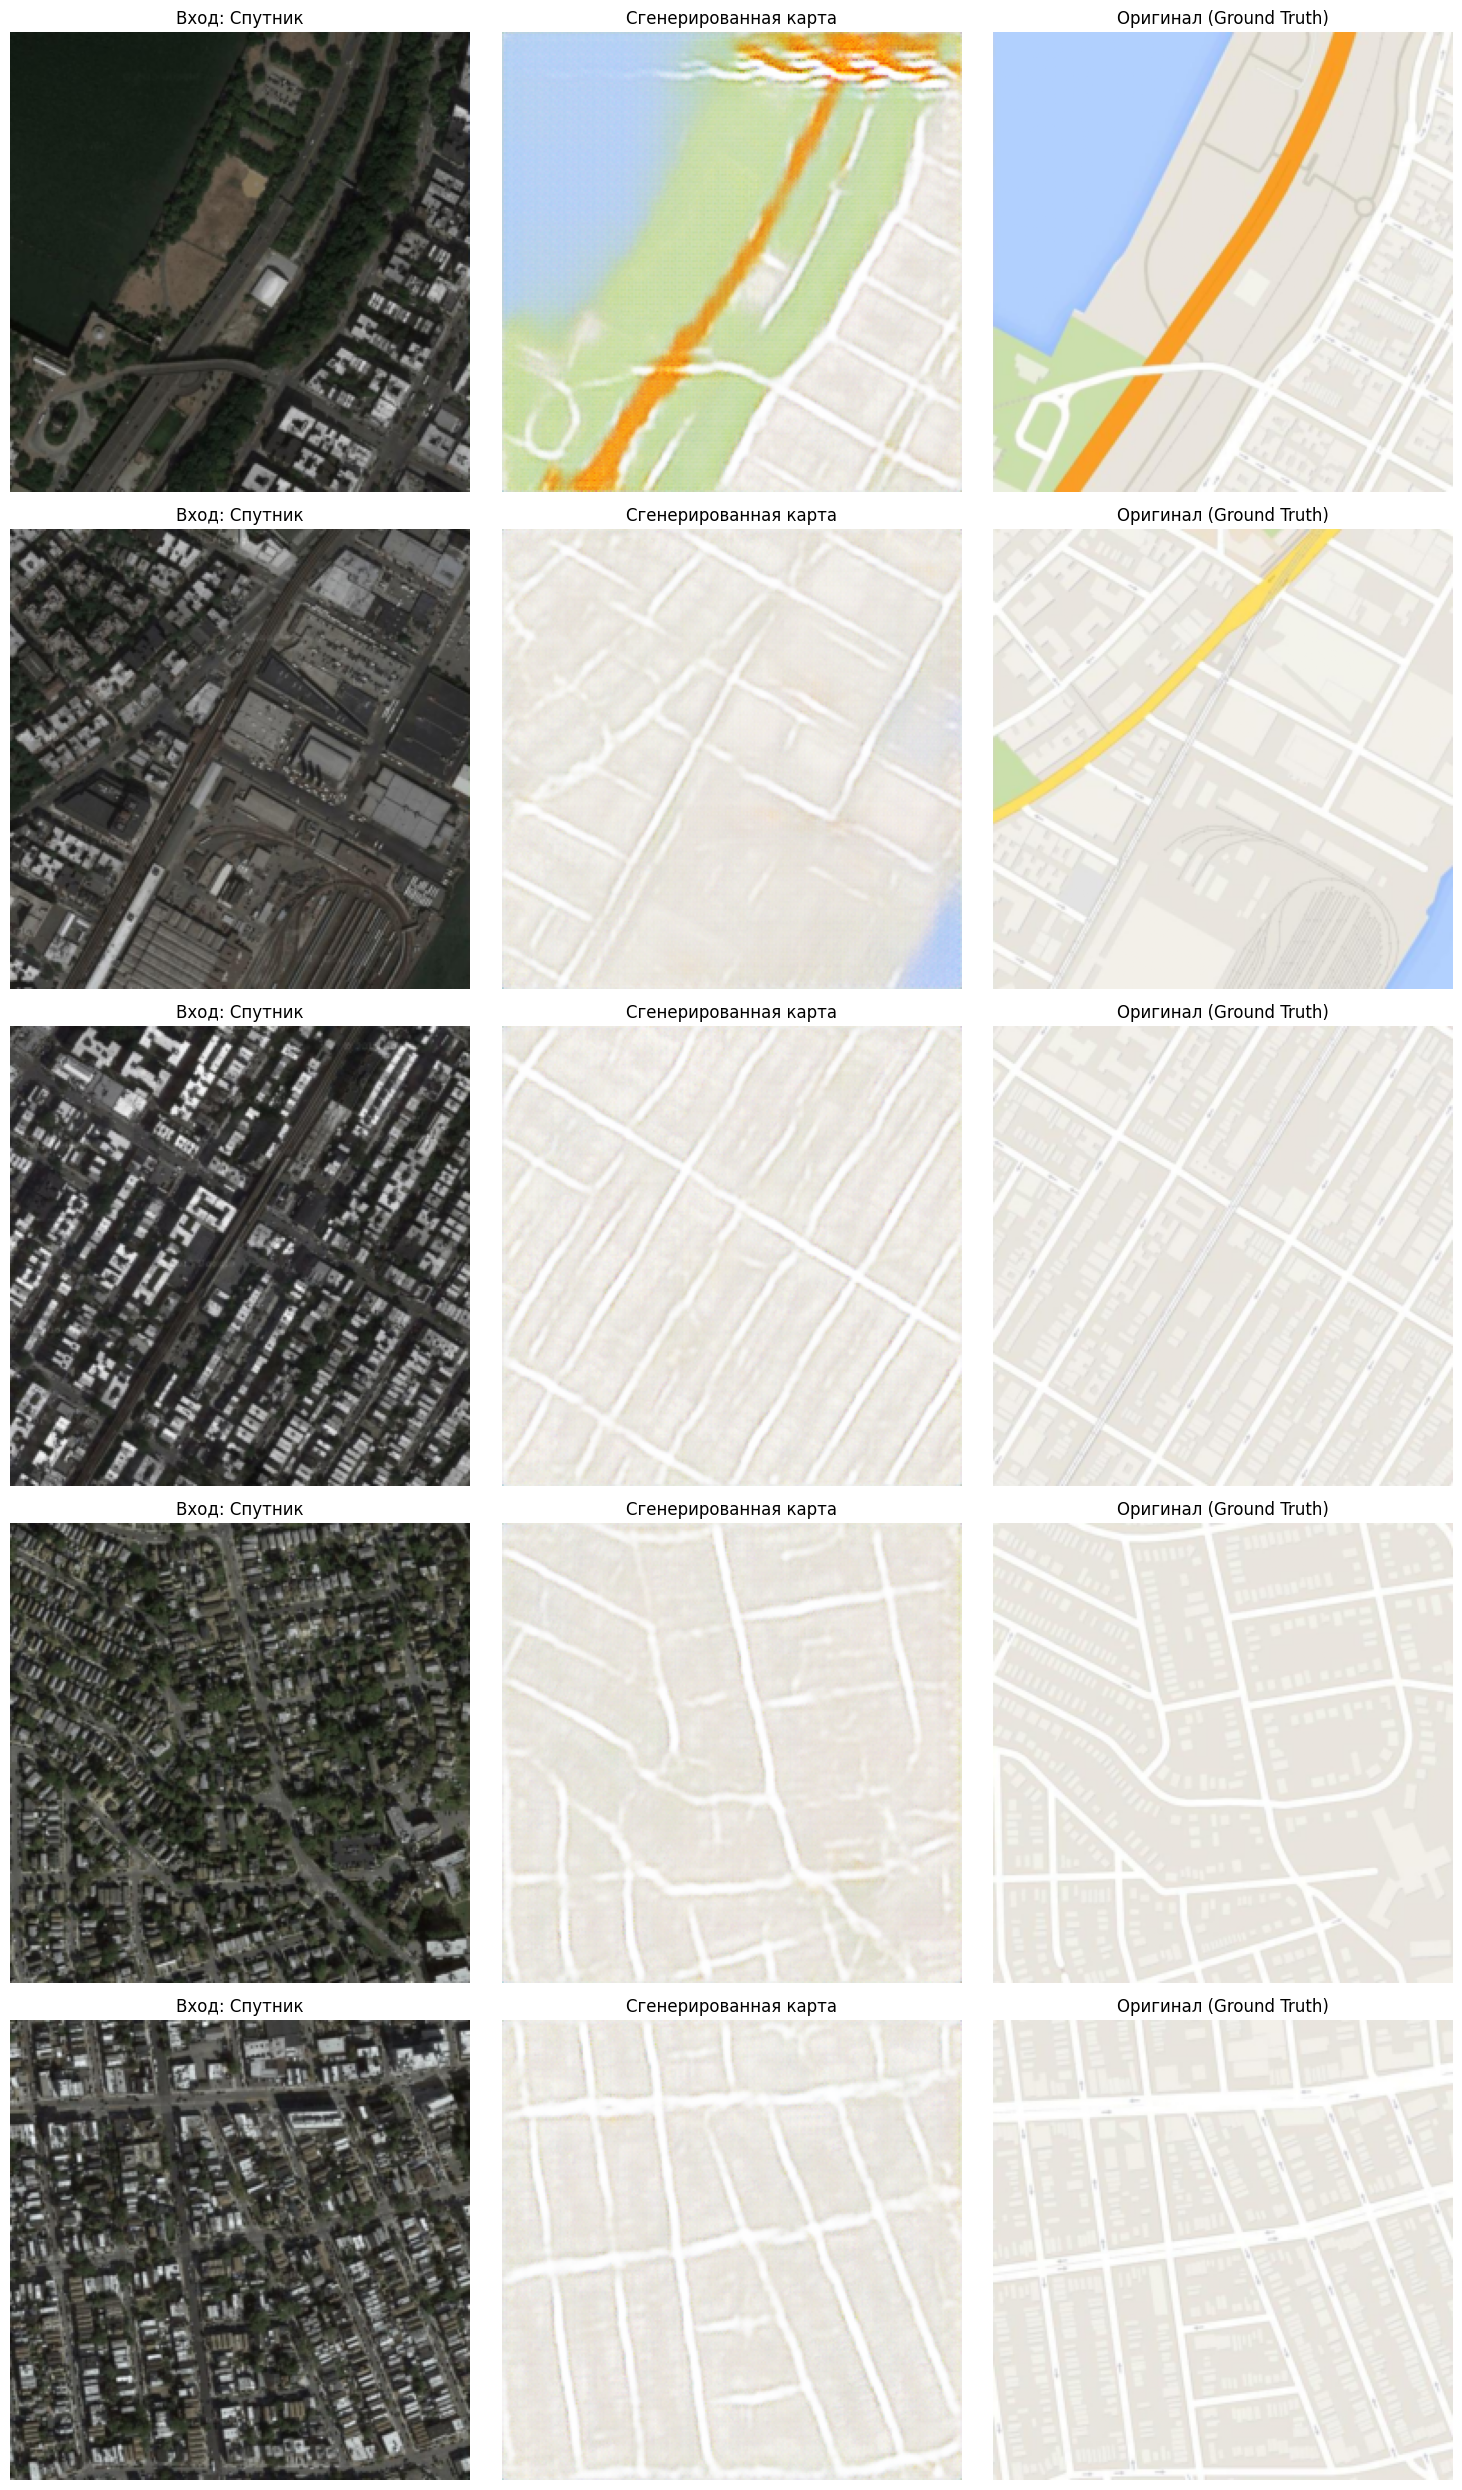

In [11]:
def plot_results(sat_imgs, gen_maps, real_maps, num_images=3):
    fig, axes = plt.subplots(num_images, 3, figsize=(15, 5 * num_images))

    for i in range(num_images):
        sat = sat_imgs[i].cpu().squeeze().permute(1, 2, 0).numpy()
        gen = gen_maps[i].cpu().squeeze().permute(1, 2, 0).numpy()
        real = real_maps[i].cpu().squeeze().permute(1, 2, 0).numpy()

        sat = np.clip((sat + 1) / 2.0, 0, 1)
        gen = np.clip((gen + 1) / 2.0, 0, 1)
        real = np.clip((real + 1) / 2.0, 0, 1)

        if num_images == 1:
            axes = [axes]

        axes[i][0].imshow(sat)
        axes[i][0].set_title('Вход: Спутник')
        axes[i][0].axis('off')

        axes[i][1].imshow(gen)
        axes[i][1].set_title('Сгенерированная карта')
        axes[i][1].axis('off')

        axes[i][2].imshow(real)
        axes[i][2].set_title('Оригинал (Ground Truth)')
        axes[i][2].axis('off')

    plt.tight_layout()
    plt.show()

# Тестирование
generator.eval()
with torch.no_grad():
    sample_sat, sample_map = next(iter(train_loader))
    sample_sat = sample_sat.to(device)
    sample_map = sample_map.to(device)
    sample_gen = generator(sample_sat)

plot_results(sample_sat, sample_gen, sample_map, num_images=5)